# MoodReach Final: what drives the reach of a social media post?

**Goal (one sentence):** predict whether and how far an original tweet spreads (retweets), and measure how much of that comes from **mood** (sentiment) versus **time**, **place**, **author** and **post format**.

| # | Question | Method | Section |
|---|---|---|---|
| Q1 | Can we classify a tweet's mood from its text? | CountVectorizer / TF-IDF + MultinomialNB vs LogisticRegression | 3 |
| Q2 | Do positive and negative tweets get different retweets? | Welch t-test (+ Mann–Whitney) | 4 |
| Q3 | Is mood independent of the weekday? | Chi-square test of independence | 4 |
| Q4 | How well can we predict retweets, and what drives them? | LinearRegression vs mean baseline; LogisticRegression for "retweeted at all" | 5 |

**Data:** 102,062 real tweets from Jan 1 – Apr 2, 2016 ([paakhim10 tweets-and-engagement-metrics](https://huggingface.co/datasets/haoxianc/paakhim10_tweets-and-engagement-metrics), MIT; Kaggle original by Paakhi Maheshwari, data from data.world/kjensen18). It replaces the midterm's 732-row dataset, which looked synthetic (section 1).

Run from inside `Final/`. Data is downloaded to `Final/data/` (git-ignored) on first run; figures go to `Final/figures/`, headline numbers to `Final/results.json`.

In [1]:
import json
import logging
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from scipy import sparse, stats
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logging.basicConfig(stream=sys.stdout, level=logging.INFO, format="%(message)s", force=True)
log = logging.getLogger("moodreach")

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
SEED = 42
RESULTS: dict = {}


def save(name: str) -> None:
    """Save the current figure for the slides."""
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")
    log.info("saved figures/%s.png", name)


def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## 0. Load and clean

In [2]:
TWEETS = hf_hub_download(
    "haoxianc/paakhim10_tweets-and-engagement-metrics",
    "tweets-engagement-metrics.csv",
    repo_type="dataset",
    local_dir="data",
)
AIRLINE = hf_hub_download(
    "osanseviero/twitter-airline-sentiment", "Tweets.csv", repo_type="dataset", local_dir="data"
)

raw = pd.read_csv(TWEETS, low_memory=False)
log.info("raw rows: %d, columns: %d", *raw.shape)
raw.head(3)

HTTP Request: HEAD https://huggingface.co/datasets/haoxianc/paakhim10_tweets-and-engagement-metrics/resolve/main/tweets-engagement-metrics.csv "HTTP/1.1 302 Found"


HTTP Request: HEAD https://huggingface.co/datasets/osanseviero/twitter-airline-sentiment/resolve/main/Tweets.csv "HTTP/1.1 302 Found"


raw rows: 102062, columns: 20


,Unnamed: 0,UserID,Gender,LocationID,City,State,StateCode,Country,TweetID,Hour,Day,Weekday,IsReshare,Reach,RetweetCount,Likes,Klout,Sentiment,Lang,text
0,0,tw-1267804344,Unknown,1.0,Elbasan,Elbasan,AL,Albania,tw-698155297102295041,7,12,Friday,True,339.0,127.0,0.0,44.0,0.0,en,"""RT @AdrianRusso82: Our Innovation Lab is offi..."
1,1,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-685159757209059329,11,7,Thursday,False,87.0,0.0,0.0,22.0,0.0,en,Now Open AWS Asia Pacific (Seoul) Region via ...
2,2,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-686907710311378944,6,12,Tuesday,False,87.0,0.0,0.0,22.0,0.0,en,A Beginner's Guide to Scaling to 11 Million+ U...


Cleaning steps, each checked against the data:

1. **Duplicate TweetIDs (2,063 rows):** the same tweet appears under more than one location row. Keep the first.
2. **Real timestamps:** Twitter IDs are "snowflakes"; the post time is `(id >> 22) + 1288834974657` ms. This lets us check the `Hour` column.
3. **Sentiment class:** the `Sentiment` column is a lexicon score (−6 … 7.3). We bin it as negative (< 0), neutral (= 0) and positive (> 0).
4. **Text features:** URL, hashtag and mention counts, reply flag, length.

In [3]:
df = raw.drop(columns=["Unnamed: 0"]).drop_duplicates("TweetID").reset_index(drop=True)
df["text"] = df["text"].str.strip().str.strip('"').str.strip()
log.info("after TweetID dedup: %d rows (-%d)", len(df), len(raw) - len(df))

tweet_id = df["TweetID"].str.replace("tw-", "", regex=False).astype("int64").to_numpy()
df["ts_utc"] = pd.to_datetime((tweet_id >> 22) + 1288834974657, unit="ms", utc=True)
log.info("post time range: %s → %s", df.ts_utc.min(), df.ts_utc.max())

# Which clock is the Hour column on? Try UTC and a few US zones.
for tz in ["UTC", "America/New_York", "America/Denver", "America/Los_Angeles"]:
    local = df.ts_utc.dt.tz_convert(tz)
    match = ((local.dt.hour == df.Hour) & (local.dt.day == df.Day)).mean()
    log.info("Hour/Day match in %-20s %.1f%%", tz, 100 * match)

after TweetID dedup: 99999 rows (-2063)


post time range: 2016-01-01 00:00:07.851000+00:00 → 2016-04-02 19:53:04.504000+00:00


Hour/Day match in UTC                  0.0%


Hour/Day match in America/New_York     0.0%


Hour/Day match in America/Denver       100.0%


Hour/Day match in America/Los_Angeles  0.0%


In [4]:
df["sent_class"] = pd.cut(
    df["Sentiment"], [-np.inf, -1e-9, 1e-9, np.inf], labels=["negative", "neutral", "positive"]
).astype(str)
df["has_url"] = df.text.str.contains(r"https?://", regex=True).astype(int)
df["n_hashtags"] = df.text.str.count(r"#\w+")
df["n_mentions"] = df.text.str.count(r"@\w+")
df["is_reply"] = df.text.str.startswith("@").astype(int)
df["text_len"] = df.text.str.len()
df["is_english"] = (df.Lang == "en").astype(int)
df["retweeted"] = (df.RetweetCount > 0).astype(int)
df["log_rt"] = np.log1p(df.RetweetCount)
df["log_reach"] = np.log1p(df.Reach)

log.info("sentiment classes:\n%s", df.sent_class.value_counts(normalize=True).round(3).to_string())
RESULTS["data"] = {
    "raw_rows": int(len(raw)),
    "rows_after_dedup": int(len(df)),
    "date_min": str(df.ts_utc.min().date()),
    "date_max": str(df.ts_utc.max().date()),
    "countries": int(df.Country.nunique()),
    "users": int(df.UserID.nunique()),
}

sentiment classes:
sent_class
neutral     0.674
positive    0.270
negative    0.056


**The `Hour` column is US Mountain time (America/Denver) for every tweet**, not the poster's local time: it matches the snowflake timestamp ~100% only in that zone. Hour-of-day effects are therefore only meaningful for US posters, and we say so on the slide.

### Reshares carry the original tweet's retweet count

For a reshare ("RT @user: …"), `RetweetCount` is the **original** tweet's count, not the reshare's: every reshare has ≥ 1 retweet. Using these rows to model reach would leak the answer, so **all engagement analysis uses original tweets only**.

In [5]:
eng_by_type = df.groupby("IsReshare").agg(
    rows=("RetweetCount", "size"),
    min_rt=("RetweetCount", "min"),
    median_rt=("RetweetCount", "median"),
    mean_rt=("RetweetCount", "mean"),
    share_retweeted=("retweeted", "mean"),
    share_liked=("Likes", lambda s: (s > 0).mean()),
)
log.info("engagement by tweet type:\n%s", eng_by_type.round(3).to_string())

orig = df[~df.IsReshare].reset_index(drop=True)
log.info(
    "original tweets: %d from %d users; %.1f%% have ≥1 retweet; median likes = %d",
    len(orig), orig.UserID.nunique(), 100 * orig.retweeted.mean(), orig.Likes.median(),
)
RESULTS["data"].update(
    original_tweets=int(len(orig)),
    original_users=int(orig.UserID.nunique()),
    original_share_retweeted=round(float(orig.retweeted.mean()), 4),
    reshare_min_rt=int(eng_by_type.loc[True, "min_rt"]),
)
eng_by_type

engagement by tweet type:
            rows  min_rt  median_rt  mean_rt  share_retweeted  share_liked
IsReshare                                                                 
False      64538     0.0        0.0    0.906            0.183        0.008
True       35461     1.0        4.0   21.057            1.000        0.000


original tweets: 64538 from 20975 users; 18.3% have ≥1 retweet; median likes = 0


,rows,min_rt,median_rt,mean_rt,share_retweeted,share_liked
IsReshare,,,,,,
False,64538,0.0,0.0,0.906319,0.183101,0.007871
True,35461,1.0,4.0,21.057218,1.000000,0.000000


Likes are almost always 0 (0.8% of originals), so **retweets are the reach target**: `log(1 + RetweetCount)` for regression and `retweeted = RetweetCount ≥ 1` for classification.

## 1. Why we left the midterm dataset

The midterm data has 732 posts, its hours fall inside 06:00–23:59, and every post is a short, generic sentence. The new data is 140× larger, covers all 24 hours and has verifiable Twitter IDs.

saved figures/1_1_old_vs_new_hours.png


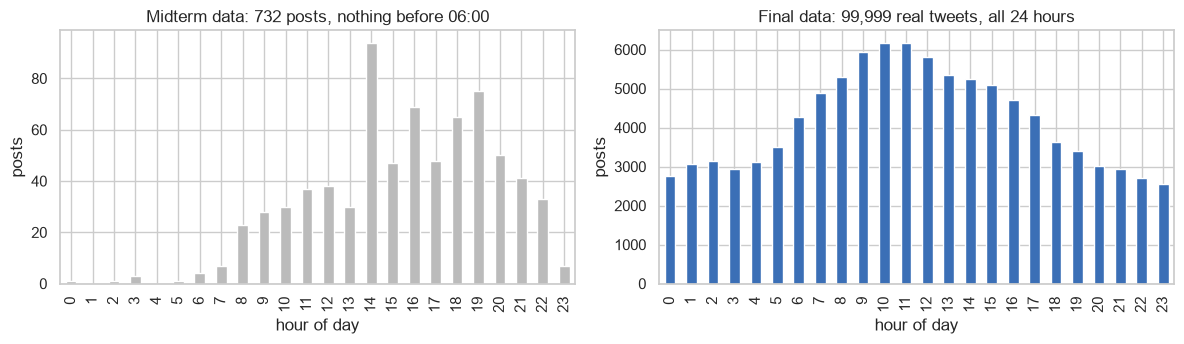

,Midterm (Kaggle sentimentdataset),Final (paakhim10 tweets)
rows,732,"99,999"
verifiable source,no,yes (snowflake IDs)
hours present,06–23 only,0–23
coverage,"3 platforms, label text","151 countries, 33k users"
engagement,"Likes, Retweets","RetweetCount, Reach, Klout"


In [6]:
mid = pd.read_csv("../Midterm-presentation/sentimentdataset.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
mid.Hour.value_counts().reindex(range(24), fill_value=0).plot.bar(ax=axes[0], color="#bbbbbb")
axes[0].set_title(f"Midterm data: {len(mid):,} posts, nothing before 06:00")
df.Hour.value_counts().reindex(range(24), fill_value=0).plot.bar(ax=axes[1], color="#3b6fb6")
axes[1].set_title(f"Final data: {len(df):,} real tweets, all 24 hours")
for ax in axes:
    ax.set_xlabel("hour of day")
    ax.set_ylabel("posts")
plt.tight_layout()
save("1_1_old_vs_new_hours")
plt.show()

comparison = pd.DataFrame(
    {
        "Midterm (Kaggle sentimentdataset)": [f"{len(mid):,}", "no", "06–23 only", "3 platforms, label text", "Likes, Retweets"],
        "Final (paakhim10 tweets)": [f"{len(df):,}", "yes (snowflake IDs)", "0–23", "151 countries, 33k users", "RetweetCount, Reach, Klout"],
    },
    index=["rows", "verifiable source", "hours present", "coverage", "engagement"],
)
comparison

## 2. EDA on real data (original tweets)

saved figures/2_1_sentiment_distribution.png


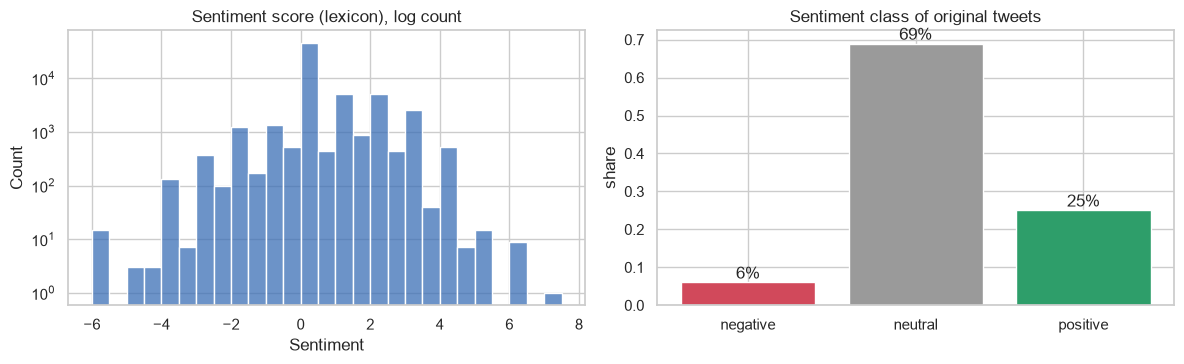

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(orig.Sentiment, bins=np.arange(-6, 7.6, 0.5), ax=axes[0], color="#3b6fb6")
axes[0].set_yscale("log")
axes[0].set_title("Sentiment score (lexicon), log count")
order = ["negative", "neutral", "positive"]
palette = {"negative": "#d1495b", "neutral": "#9a9a9a", "positive": "#2e9e6a"}
share = orig.sent_class.value_counts(normalize=True).reindex(order)
axes[1].bar(order, share, color=[palette[c] for c in order])
for i, v in enumerate(share):
    axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")
axes[1].set_title("Sentiment class of original tweets")
axes[1].set_ylabel("share")
plt.tight_layout()
save("2_1_sentiment_distribution")
plt.show()

saved figures/2_2_retweet_distribution.png


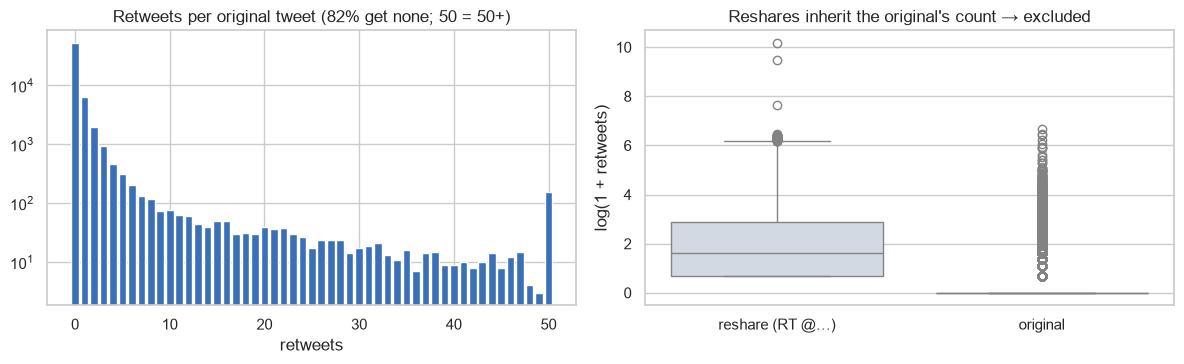

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
counts = orig.RetweetCount.clip(upper=50).value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color="#3b6fb6")
axes[0].set_yscale("log")
axes[0].set_title(f"Retweets per original tweet ({1 - orig.retweeted.mean():.0%} get none; 50 = 50+)")
axes[0].set_xlabel("retweets")
sns.boxplot(
    data=df.assign(type=np.where(df.IsReshare, "reshare (RT @…)", "original")),
    x="type", y="log_rt", ax=axes[1], color="#cfd8e6",
)
axes[1].set_title("Reshares inherit the original's count → excluded")
axes[1].set_ylabel("log(1 + retweets)")
axes[1].set_xlabel("")
plt.tight_layout()
save("2_2_retweet_distribution")
plt.show()

Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


saved figures/2_3_rate_by_sentiment_time.png


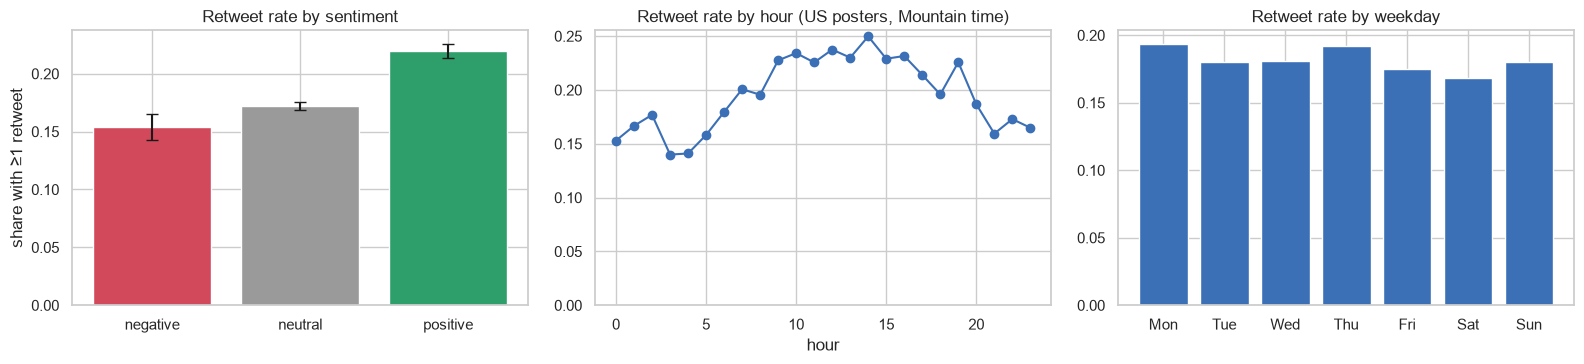

In [9]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
us = orig[orig.Country == "United States"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_by_sent = orig.groupby("sent_class").retweeted.agg(["mean", "sem"]).reindex(order)
axes[0].bar(order, rate_by_sent["mean"], yerr=1.96 * rate_by_sent["sem"], color=[palette[c] for c in order], capsize=4)
axes[0].set_title("Retweet rate by sentiment")
axes[0].set_ylabel("share with ≥1 retweet")
rate_by_hour = us.groupby("Hour").retweeted.mean()
axes[1].plot(rate_by_hour.index, rate_by_hour.values, marker="o", color="#3b6fb6")
axes[1].set_title("Retweet rate by hour (US posters, Mountain time)")
axes[1].set_xlabel("hour")
rate_by_day = orig.groupby("Weekday").retweeted.mean().reindex(weekday_order)
axes[2].bar([d[:3] for d in weekday_order], rate_by_day.values, color="#3b6fb6")
axes[2].set_title("Retweet rate by weekday")
for ax in axes[1:]:
    ax.set_ylim(0, None)
plt.tight_layout()
save("2_3_rate_by_sentiment_time")
plt.show()

saved figures/2_4_countries.png


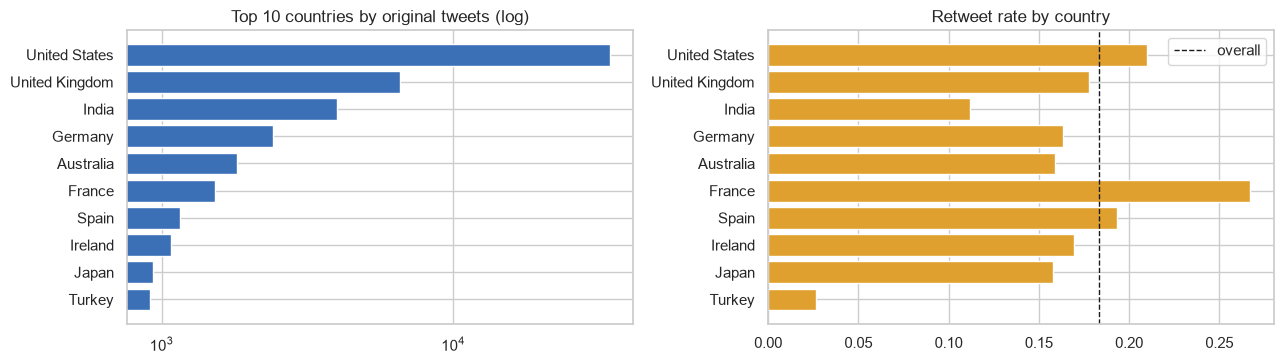

,tweets,retweet_rate,positive
Country,,,
United States,34510,0.210,0.251
United Kingdom,6570,0.178,0.283
India,4007,0.112,0.231
Germany,2414,0.164,0.243
Australia,1818,0.159,0.271
France,1521,0.267,0.302
Spain,1158,0.193,0.240
Ireland,1080,0.169,0.227
Japan,938,0.158,0.199


In [10]:
top_countries = orig.Country.value_counts().head(10).index
by_country = (
    orig[orig.Country.isin(top_countries)]
    .groupby("Country")
    .agg(tweets=("retweeted", "size"), retweet_rate=("retweeted", "mean"), positive=("sent_class", lambda s: (s == "positive").mean()))
    .sort_values("tweets", ascending=False)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(by_country.index[::-1], by_country.tweets[::-1], color="#3b6fb6")
axes[0].set_xscale("log")
axes[0].set_title("Top 10 countries by original tweets (log)")
axes[1].barh(by_country.index[::-1], by_country.retweet_rate[::-1], color="#e0a030")
axes[1].axvline(orig.retweeted.mean(), color="k", ls="--", lw=1, label="overall")
axes[1].set_title("Retweet rate by country")
axes[1].legend()
plt.tight_layout()
save("2_4_countries")
plt.show()
by_country.round(3)

saved figures/2_5_author_and_correlation.png


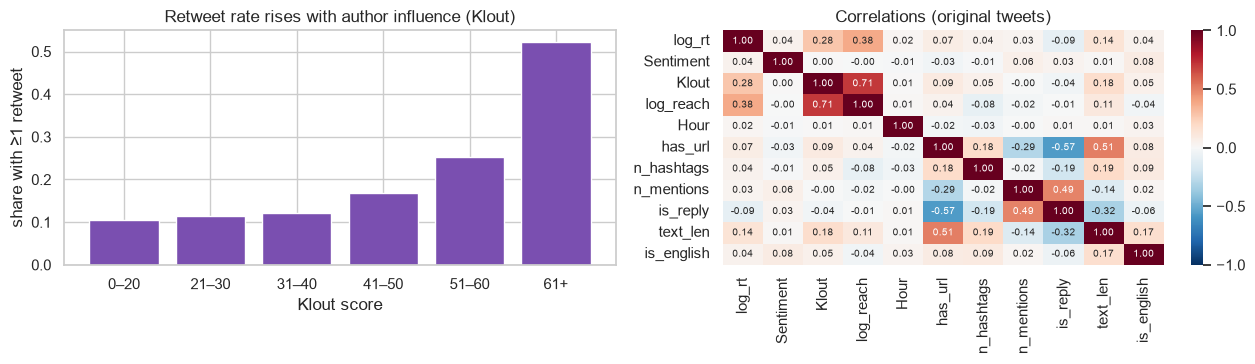

corr with log retweets:
is_reply     -0.090
Hour          0.020
n_mentions    0.031
Sentiment     0.041
is_english    0.041
n_hashtags    0.045
has_url       0.072
text_len      0.138
Klout         0.277
log_reach     0.378


,tweets,retweet_rate,mean_rt
klout_bin,,,
0–20,5370,0.106,0.236
21–30,7214,0.114,0.198
31–40,11629,0.121,0.216
41–50,26426,0.168,0.406
51–60,9946,0.252,0.698
61+,3953,0.523,9.007


In [11]:
orig["klout_bin"] = pd.cut(orig.Klout, [-1, 20, 30, 40, 50, 60, 100], labels=["0–20", "21–30", "31–40", "41–50", "51–60", "61+"])
by_klout = orig.groupby("klout_bin", observed=True).agg(tweets=("retweeted", "size"), retweet_rate=("retweeted", "mean"), mean_rt=("RetweetCount", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(by_klout.index.astype(str), by_klout.retweet_rate, color="#7a4fb0")
axes[0].set_title("Retweet rate rises with author influence (Klout)")
axes[0].set_xlabel("Klout score")
axes[0].set_ylabel("share with ≥1 retweet")
num_cols = ["log_rt", "Sentiment", "Klout", "log_reach", "Hour", "has_url", "n_hashtags", "n_mentions", "is_reply", "text_len", "is_english"]
sns.heatmap(orig[num_cols].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlations (original tweets)")
plt.tight_layout()
save("2_5_author_and_correlation")
plt.show()
log.info("corr with log retweets:\n%s", orig[num_cols].corr()["log_rt"].drop("log_rt").sort_values().round(3).to_string())
by_klout.round(3)

top account tw-66780587: 785 tweets, 43% of all original retweets; top 1% of users: 75%


saved figures/2_6_reach_concentration.png


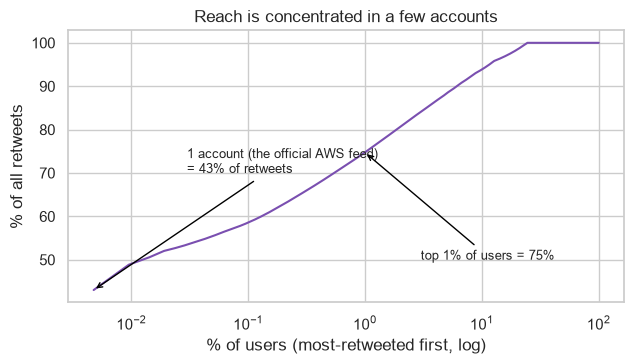

In [12]:
user_rt = orig.groupby("UserID").RetweetCount.sum().sort_values(ascending=False)
top_user = user_rt.index[0]
top_share = user_rt.iloc[0] / user_rt.sum()
top1pct_share = user_rt.head(max(1, len(user_rt) // 100)).sum() / user_rt.sum()
log.info(
    "top account %s: %d tweets, %.0f%% of all original retweets; top 1%% of users: %.0f%%",
    top_user, (orig.UserID == top_user).sum(), 100 * top_share, 100 * top1pct_share,
)
cum = user_rt.cumsum() / user_rt.sum()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color="#7a4fb0")
ax.set_xscale("log")
ax.set_xlabel("% of users (most-retweeted first, log)")
ax.set_ylabel("% of all retweets")
ax.annotate(f"1 account (the official AWS feed)\n= {top_share:.0%} of retweets", xy=(100 / len(cum), top_share * 100), xytext=(0.03, 70), arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=9)
ax.annotate(f"top 1% of users = {top1pct_share:.0%}", xy=(1, top1pct_share * 100), xytext=(3, 50), arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=9)
ax.set_title("Reach is concentrated in a few accounts")
plt.tight_layout()
save("2_6_reach_concentration")
plt.show()
RESULTS["data"].update(top_account_share=round(float(top_share), 4), top1pct_users_share=round(float(top1pct_share), 4))

**One account earns ~43% of all retweets, and 1% of users earn ~75%.** If such an account lands in the test set, the test score swings wildly: before this fix, LinearRegression's 5-fold R² ranged from −0.03 to 0.18. For the tests and models below, **each user contributes at most 20 randomly chosen tweets**. This also makes the observations closer to independent, which t-tests and chi-square tests assume.

In [13]:
CAP = 20
rank = orig.assign(_r=np.random.default_rng(SEED).random(len(orig))).groupby("UserID")._r.rank(method="first")
capped = orig[rank <= CAP].reset_index(drop=True)
log.info("capped sample: %d tweets from %d users (≤%d each); retweet rate %.3f", len(capped), capped.UserID.nunique(), CAP, capped.retweeted.mean())
RESULTS["data"].update(cap_per_user=CAP, capped_tweets=int(len(capped)))

capped sample: 48822 tweets from 20975 users (≤20 each); retweet rate 0.179


**EDA takeaways (top 3):**

1. **Reach is rare and concentrated:** about 82% of original tweets get no retweet, and 1% of accounts collect three quarters of all retweets.
2. **The author matters most:** the retweet rate climbs steadily with Klout and Reach (follower count); these are the strongest correlations with retweets. Reach grows slowly per user over the quarter and is unrelated to a single tweet's retweets within a user, so it is an author trait, not a leaked outcome.
3. **Mood barely moves reach:** the retweet rates of positive, neutral and negative tweets are within a few points of each other (tested formally in section 4).

## 3. Q1 — Sentiment classifier from text

The labels come from a word lexicon, so the text decides the label. A high score on this data alone is therefore expected and does not prove the model understands mood. As an honest check we also test on **14,640 airline tweets labeled by humans** (a different topic and different labelers).

In [14]:
texts = df.drop_duplicates("text")[["text", "sent_class"]].reset_index(drop=True)
log.info("unique texts for the classifier: %d (dedup prevents the same text landing in train and test)", len(texts))
X_tr_txt, X_te_txt, y_tr_s, y_te_s = train_test_split(
    texts.text, texts.sent_class, test_size=0.2, stratify=texts.sent_class, random_state=SEED
)

candidates = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Count + MultinomialNB": make_pipeline(CountVectorizer(min_df=2), MultinomialNB()),
    "TF-IDF + MultinomialNB": make_pipeline(TfidfVectorizer(min_df=2), MultinomialNB()),
    "Count + LogisticRegression": make_pipeline(CountVectorizer(min_df=2), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "TF-IDF + LogisticRegression": make_pipeline(TfidfVectorizer(min_df=2, ngram_range=(1, 2)), LogisticRegression(max_iter=2000, C=10, class_weight="balanced")),
}
rows = []
for name, model in candidates.items():
    model.fit(X_tr_txt, y_tr_s)
    pred = model.predict(X_te_txt)
    rows.append({"model": name, "accuracy": accuracy_score(y_te_s, pred), "macro_F1": f1_score(y_te_s, pred, average="macro")})
    log.info("%-28s acc=%.3f macroF1=%.3f", name, rows[-1]["accuracy"], rows[-1]["macro_F1"])
clf_table = pd.DataFrame(rows).set_index("model").round(3)
clf_table

unique texts for the classifier: 70256 (dedup prevents the same text landing in train and test)


Majority baseline            acc=0.671 macroF1=0.268


Count + MultinomialNB        acc=0.770 macroF1=0.681


TF-IDF + MultinomialNB       acc=0.781 macroF1=0.530


Count + LogisticRegression   acc=0.894 macroF1=0.822


TF-IDF + LogisticRegression  acc=0.900 macroF1=0.827


,accuracy,macro_F1
model,,
Majority baseline,0.671,0.268
Count + MultinomialNB,0.770,0.681
TF-IDF + MultinomialNB,0.781,0.530
Count + LogisticRegression,0.894,0.822
TF-IDF + LogisticRegression,0.900,0.827


Macro-F1 averages the three classes equally, so it is the fair metric here: only 6% of tweets are negative, and the majority baseline already reaches ~66% accuracy by always guessing "neutral".

best: TF-IDF + LogisticRegression; 5-fold CV macro-F1 = 0.812 ± 0.003


Count + MultinomialNB 5-fold CV macro-F1 = 0.677 ± 0.004


              precision    recall  f1-score   support

    negative      0.679     0.694     0.686       855
     neutral      0.934     0.937     0.935      9430
    positive      0.865     0.855     0.860      3767

    accuracy                          0.900     14052
   macro avg      0.826     0.828     0.827     14052
weighted avg      0.900     0.900     0.900     14052



saved figures/3_1_classifier_confusion_words.png


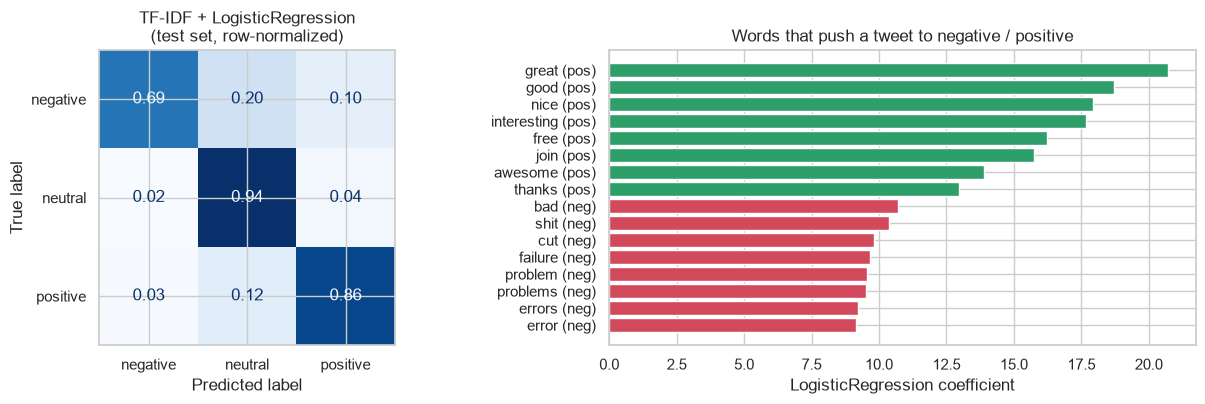

In [15]:
best_name = clf_table.macro_F1.drop("Majority baseline").idxmax()
best_clf = candidates[best_name]
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_f1 = cross_val_score(best_clf, X_tr_txt, y_tr_s, cv=cv, scoring="f1_macro", n_jobs=-1)
nb_cv_f1 = cross_val_score(candidates["Count + MultinomialNB"], X_tr_txt, y_tr_s, cv=cv, scoring="f1_macro", n_jobs=-1)
log.info("best: %s; 5-fold CV macro-F1 = %.3f ± %.3f", best_name, cv_f1.mean(), cv_f1.std())
log.info("Count + MultinomialNB 5-fold CV macro-F1 = %.3f ± %.3f", nb_cv_f1.mean(), nb_cv_f1.std())
pred_best = best_clf.predict(X_te_txt)
print(classification_report(y_te_s, pred_best, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ConfusionMatrixDisplay.from_predictions(y_te_s, pred_best, labels=order, normalize="true", values_format=".2f", cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"{best_name}\n(test set, row-normalized)")

lr_step = best_clf.named_steps["logisticregression"]
vocab = np.array(best_clf.named_steps[best_clf.steps[0][0]].get_feature_names_out())
top_words = []
for cls in ["negative", "positive"]:
    k = list(lr_step.classes_).index(cls)
    idx = np.argsort(lr_step.coef_[k])[-8:]
    top_words += [(w, c, cls) for w, c in zip(vocab[idx], lr_step.coef_[k][idx])]
tw = pd.DataFrame(top_words, columns=["word", "coef", "class"])
axes[1].barh(tw.word + " (" + tw["class"].str[:3] + ")", tw.coef, color=tw["class"].map(palette))
axes[1].set_title("Words that push a tweet to negative / positive")
axes[1].set_xlabel("LogisticRegression coefficient")
plt.tight_layout()
save("3_1_classifier_confusion_words")
plt.show()

In [16]:
air = pd.read_csv(AIRLINE)[["text", "airline_sentiment"]]
air_pred = best_clf.predict(air.text)
air_nb_pred = candidates["Count + MultinomialNB"].predict(air.text)
air_major = air.airline_sentiment.value_counts(normalize=True).max()
air_rows = pd.DataFrame(
    {
        "Majority baseline (always 'negative')": [air_major, f1_score(air.airline_sentiment, ["negative"] * len(air), average="macro")],
        "Count + MultinomialNB": [accuracy_score(air.airline_sentiment, air_nb_pred), f1_score(air.airline_sentiment, air_nb_pred, average="macro")],
        best_name: [accuracy_score(air.airline_sentiment, air_pred), f1_score(air.airline_sentiment, air_pred, average="macro")],
    },
    index=["accuracy", "macro_F1"],
).T.round(3)
log.info("transfer to human-labeled airline tweets:\n%s", air_rows.to_string())
log.info("recall on human 'negative' tweets: %.3f", recall_score(air.airline_sentiment, air_pred, labels=["negative"], average="macro"))
air_rows

transfer to human-labeled airline tweets:
                                       accuracy  macro_F1
Majority baseline (always 'negative')     0.627     0.257
Count + MultinomialNB                     0.589     0.473
TF-IDF + LogisticRegression               0.528     0.494


recall on human 'negative' tweets: 0.492


,accuracy,macro_F1
Majority baseline (always 'negative'),0.627,0.257
Count + MultinomialNB,0.589,0.473
TF-IDF + LogisticRegression,0.528,0.494


saved figures/3_2_airline_transfer.png


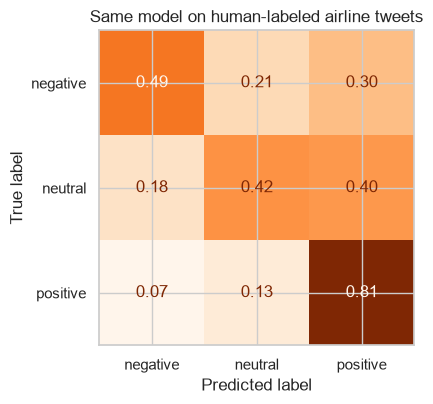

In [17]:
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(air.airline_sentiment, air_pred, labels=order, normalize="true", values_format=".2f", cmap="Oranges", ax=ax, colorbar=False)
ax.set_title("Same model on human-labeled airline tweets")
plt.tight_layout()
save("3_2_airline_transfer")
plt.show()

RESULTS["classifier"] = {
    "table_test": clf_table.reset_index().to_dict("records"),
    "best": best_name,
    "best_cv_macro_f1_mean": round(float(cv_f1.mean()), 4),
    "best_cv_macro_f1_std": round(float(cv_f1.std()), 4),
    "nb_cv_macro_f1_mean": round(float(nb_cv_f1.mean()), 4),
    "airline_transfer": air_rows.reset_index().rename(columns={"index": "model"}).to_dict("records"),
}

**Q1 answer:** on the lexicon labels, LogisticRegression beats MultinomialNB, and both far exceed the baseline. On human-labeled airline tweets the same model drops sharply: it misses most complaints that use no "negative" word (for example "my flight was delayed 3 hours"). The model learned the lexicon, not human mood, and this is a limitation we report.

## 4. Hypothesis tests (capped sample: ≤ 20 tweets per user)

### Q2: Do positive and negative tweets get different retweets?

H₀: mean log(1 + retweets) is equal for positive and negative tweets. We use Welch's t-test (unequal variances), with Mann–Whitney U as a check because the data are skewed. With tens of thousands of rows even tiny differences become "significant", so we also report the effect size (Cohen's d).

In [18]:
pos = capped.loc[capped.sent_class == "positive", "log_rt"]
neg = capped.loc[capped.sent_class == "negative", "log_rt"]
t_stat, t_p = stats.ttest_ind(pos, neg, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(pos, neg, alternative="two-sided")
pooled_sd = np.sqrt(((len(pos) - 1) * pos.var() + (len(neg) - 1) * neg.var()) / (len(pos) + len(neg) - 2))
cohen_d = (pos.mean() - neg.mean()) / pooled_sd
h1 = {
    "n_positive": int(len(pos)),
    "n_negative": int(len(neg)),
    "mean_rt_positive": round(float(np.expm1(pos).mean()), 3),
    "mean_rt_negative": round(float(np.expm1(neg).mean()), 3),
    "rate_positive": round(float((pos > 0).mean()), 4),
    "rate_negative": round(float((neg > 0).mean()), 4),
    "welch_t": round(float(t_stat), 3),
    "welch_p": float(f"{t_p:.3g}"),
    "mannwhitney_p": float(f"{u_p:.3g}"),
    "cohen_d": round(float(cohen_d), 3),
}
log.info("H1 positive vs negative: %s", h1)
RESULTS["h1_ttest"] = h1
pd.Series(h1)

H1 positive vs negative: {'n_positive': 12861, 'n_negative': 3386, 'mean_rt_positive': 0.599, 'mean_rt_negative': 0.463, 'rate_positive': 0.2087, 'rate_negative': 0.1527, 'welch_t': 6.748, 'welch_p': 1.65e-11, 'mannwhitney_p': 3.46e-13, 'cohen_d': 0.121}


n_positive          1.286100e+04
n_negative          3.386000e+03
mean_rt_positive    5.990000e-01
mean_rt_negative    4.630000e-01
rate_positive       2.087000e-01
rate_negative       1.527000e-01
welch_t             6.748000e+00
welch_p             1.650000e-11
mannwhitney_p       3.460000e-13
cohen_d             1.210000e-01
dtype: float64

### Q3: Is mood independent of the weekday?

H₀: sentiment class and weekday are independent. We use a chi-square test of independence, with Cramér's V as the effect size (0 = independent, 1 = fully determined).

H2 sentiment x weekday: {'chi2': 91.17, 'dof': 12, 'p': 2.93e-14, 'cramers_v': 0.0306}


saved figures/4_1_hypothesis_tests.png


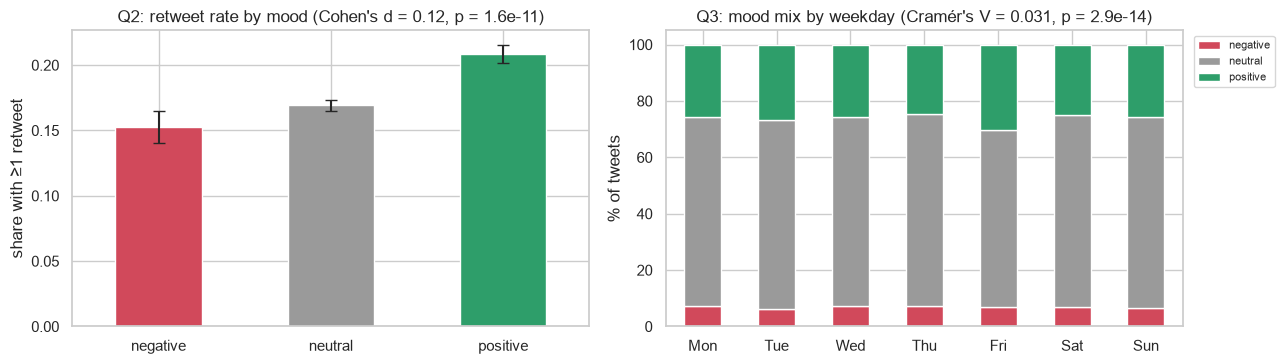

sent_class,negative,neutral,positive
Weekday,,,
Monday,530,5007,1920
Tuesday,565,6089,2435
Wednesday,658,6029,2332
Thursday,670,6144,2213
Friday,510,4668,2235
Saturday,238,2345,864
Sunday,215,2293,862


In [19]:
ct = pd.crosstab(capped.Weekday, capped.sent_class).reindex(weekday_order)
chi2, chi_p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
h2 = {"chi2": round(float(chi2), 2), "dof": int(dof), "p": float(f"{chi_p:.3g}"), "cramers_v": round(float(cramers_v), 4)}
log.info("H2 sentiment x weekday: %s", h2)
RESULTS["h2_chi2"] = h2

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rate_cap = capped.groupby("sent_class").retweeted.agg(["mean", "sem"]).reindex(order)
rate_cap.assign(cls=order).plot.bar(x="cls", y="mean", yerr=1.96 * rate_cap["sem"], ax=axes[0], color=[palette[c] for c in order], legend=False, capsize=4, rot=0)
axes[0].set_title(f"Q2: retweet rate by mood (Cohen's d = {cohen_d:.2f}, p = {t_p:.2g})")
axes[0].set_xlabel("")
axes[0].set_ylabel("share with ≥1 retweet")
(ct.div(ct.sum(axis=1), axis=0)[order] * 100).set_index(pd.Index([d[:3] for d in weekday_order])).plot.bar(stacked=True, ax=axes[1], color=[palette[c] for c in order], rot=0)
axes[1].set_title(f"Q3: mood mix by weekday (Cramér's V = {cramers_v:.3f}, p = {chi_p:.2g})")
axes[1].set_ylabel("% of tweets")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
save("4_1_hypothesis_tests")
plt.show()
ct

**Reading the tests:** a small p-value only tells us the difference is not zero. Cohen's d below 0.2 and Cramér's V below 0.1 both count as negligible, so mood has at most a tiny link to retweets and to the weekday.

## 5. Q4 — Predicting retweets

**Target:** `log(1 + RetweetCount)` of original tweets (capped sample).
**Features (all known when the tweet is posted):**

- mood: sentiment score plus positive/negative flags
- author: Klout, log(Reach)
- time: weekday and time-of-day bin (Mountain time)
- place: top-10 countries, plus an "other" group
- post format: URL, hashtags, mentions, reply, length, English
- gender

**Split:** by **user** (GroupShuffleSplit, 80/20). Some users post hundreds of tweets, so a random split would let the model memorize authors and look better than it is.

In [20]:
def build_features(frame: pd.DataFrame, countries: pd.Index) -> pd.DataFrame:
    """Feature matrix for the engagement models (one-hot categories, no leakage columns)."""
    tod = pd.cut(frame.Hour, [-1, 5, 11, 17, 23], labels=["night", "morning", "afternoon", "evening"])
    X = pd.DataFrame(
        {
            "sentiment_score": frame.Sentiment,
            "is_positive": (frame.sent_class == "positive").astype(int),
            "is_negative": (frame.sent_class == "negative").astype(int),
            "klout": frame.Klout,
            "log_reach": frame.log_reach,
            "has_url": frame.has_url,
            "n_hashtags": frame.n_hashtags,
            "n_mentions": frame.n_mentions,
            "is_reply": frame.is_reply,
            "text_len": frame.text_len,
            "is_english": frame.is_english,
        }
    )
    cats = pd.DataFrame(
        {
            "weekday": frame.Weekday,
            "tod": tod.astype(str),
            "country": frame.Country.where(frame.Country.isin(countries), "Other"),
            "gender": frame.Gender,
        }
    )
    dummies = pd.get_dummies(cats, drop_first=False, dtype=int)
    # drop one reference level per category so LinearRegression coefficients are identifiable
    dummies = dummies.drop(columns=["weekday_Monday", "tod_morning", "country_United States", "gender_Unknown"])
    return pd.concat([X, dummies], axis=1)


GROUPS = {
    "mood": ["sentiment_score", "is_positive", "is_negative"],
    "author": ["klout", "log_reach"],
    "time": lambda c: c.startswith(("weekday_", "tod_")),
    "place": lambda c: c.startswith("country_") or c == "is_english",
    "post format": ["has_url", "n_hashtags", "n_mentions", "is_reply", "text_len"],
    "gender": lambda c: c.startswith("gender_"),
}


def group_cols(group: str, cols: pd.Index) -> list:
    rule = GROUPS[group]
    return [c for c in cols if (rule(c) if callable(rule) else c in rule)]


X_all = build_features(capped, top_countries)
y_all = capped.log_rt.to_numpy()
yb_all = capped.retweeted.to_numpy()
users = capped.UserID.to_numpy()
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X_all, y_all, groups=users))
X_tr, X_te = X_all.iloc[tr_idx], X_all.iloc[te_idx]
y_tr, y_te = y_all[tr_idx], y_all[te_idx]
yb_tr, yb_te = yb_all[tr_idx], yb_all[te_idx]
assert not set(users[tr_idx]) & set(users[te_idx]), "a user is in both train and test"
log.info("train %d tweets / %d users, test %d tweets / %d users, %d features", len(tr_idx), len(set(users[tr_idx])), len(te_idx), len(set(users[te_idx])), X_all.shape[1])
assert sum(len(group_cols(g, X_all.columns)) for g in GROUPS) == X_all.shape[1], "every feature belongs to exactly one group"

train 39358 tweets / 16780 users, test 9464 tweets / 4195 users, 33 features


In [21]:
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)
linreg = LinearRegression().fit(Xs_tr, y_tr)
baseline_pred = np.full_like(y_te, y_tr.mean())


def reg_metrics(y_true, y_pred) -> dict:
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": rmse(y_true, y_pred), "R2": r2_score(y_true, y_pred)}


reg_table = pd.DataFrame(
    {
        "Mean baseline (test)": reg_metrics(y_te, baseline_pred),
        "LinearRegression (train)": reg_metrics(y_tr, linreg.predict(Xs_tr)),
        "LinearRegression (test)": reg_metrics(y_te, linreg.predict(Xs_te)),
    }
).T.round(4)
cv_r2 = cross_val_score(
    make_pipeline(StandardScaler(), LinearRegression()), X_all, y_all, groups=users, cv=GroupKFold(5), scoring="r2"
)
log.info("regression:\n%s", reg_table.to_string())
log.info("5-fold GroupKFold R² = %.3f ± %.3f (folds: %s)", cv_r2.mean(), cv_r2.std(), np.round(cv_r2, 3))
reg_table

regression:
                             MAE    RMSE      R2
Mean baseline (test)      0.3085  0.4664 -0.0001
LinearRegression (train)  0.2913  0.4563  0.1019
LinearRegression (test)   0.2878  0.4454  0.0879


5-fold GroupKFold R² = 0.094 ± 0.020 (folds: [0.086 0.06  0.097 0.111 0.114])


,MAE,RMSE,R2
Mean baseline (test),0.3085,0.4664,-0.0001
LinearRegression (train),0.2913,0.4563,0.1019
LinearRegression (test),0.2878,0.4454,0.0879


On the original scale, an MAE in log units is a multiplicative error: an MAE of 0.3 means the prediction is typically off by a factor of about e^0.3 ≈ 1.35 in (1 + retweets).

### Which feature groups matter? (drop-one-group ablation)

We refit the model without each group and measure how much test R² falls. A large drop means the group carries information the others do not.

In [22]:
full_r2 = r2_score(y_te, linreg.predict(Xs_te))
ablation = {}
for g in GROUPS:
    keep = [c for c in X_all.columns if c not in group_cols(g, X_all.columns)]
    sc = StandardScaler().fit(X_tr[keep])
    m = LinearRegression().fit(sc.transform(X_tr[keep]), y_tr)
    ablation[g] = full_r2 - r2_score(y_te, m.predict(sc.transform(X_te[keep])))
    only = StandardScaler().fit(X_tr[group_cols(g, X_all.columns)])
    m_only = LinearRegression().fit(only.transform(X_tr[group_cols(g, X_all.columns)]), y_tr)
    ablation[g] = (ablation[g], r2_score(y_te, m_only.predict(only.transform(X_te[group_cols(g, X_all.columns)]))))
abl = pd.DataFrame(ablation, index=["R2 drop when removed", "R2 using this group alone"]).T.sort_values("R2 drop when removed", ascending=False)
log.info("ablation (full test R² = %.4f):\n%s", full_r2, abl.round(4).to_string())
abl.round(4)

ablation (full test R² = 0.0879):
             R2 drop when removed  R2 using this group alone
author                     0.0444                     0.0420
post format                0.0362                     0.0395
place                      0.0055                     0.0045
mood                       0.0015                     0.0012
time                       0.0005                     0.0004
gender                     0.0003                     0.0000


,R2 drop when removed,R2 using this group alone
author,0.0444,0.0420
post format,0.0362,0.0395
place,0.0055,0.0045
mood,0.0015,0.0012
time,0.0005,0.0004
gender,0.0003,0.0000


### Did it get retweeted at all? (LogisticRegression)

Because 82% of tweets get zero retweets, the yes/no question is the more useful one. Its coefficients on standardized features are the **drivers chart**: each bar shows how a 1-SD change in a feature multiplies the odds of being retweeted.

In [23]:
logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xs_tr, yb_tr)
prob_te = logreg.predict_proba(Xs_te)[:, 1]
pred_te = (prob_te >= 0.5).astype(int)
majority = DummyClassifier(strategy="most_frequent").fit(Xs_tr, yb_tr)
mood_only_cols = group_cols("mood", X_all.columns)
logreg_mood = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr[mood_only_cols], yb_tr)
logit_table = pd.DataFrame(
    {
        "Majority baseline (never retweeted)": {"accuracy": accuracy_score(yb_te, majority.predict(Xs_te)), "precision": 0.0, "recall": 0.0, "ROC_AUC": 0.5},
        "Mood features only": {
            "accuracy": accuracy_score(yb_te, logreg_mood.predict(X_te[mood_only_cols])),
            "precision": precision_score(yb_te, logreg_mood.predict(X_te[mood_only_cols]), zero_division=0),
            "recall": recall_score(yb_te, logreg_mood.predict(X_te[mood_only_cols])),
            "ROC_AUC": roc_auc_score(yb_te, logreg_mood.predict_proba(X_te[mood_only_cols])[:, 1]),
        },
        "All features": {"accuracy": accuracy_score(yb_te, pred_te), "precision": precision_score(yb_te, pred_te), "recall": recall_score(yb_te, pred_te), "ROC_AUC": roc_auc_score(yb_te, prob_te)},
    }
).T.round(3)
log.info("retweeted yes/no:\n%s", logit_table.to_string())
logit_table

retweeted yes/no:
                                     accuracy  precision  recall  ROC_AUC
Majority baseline (never retweeted)     0.821      0.000   0.000    0.500
Mood features only                      0.669      0.203   0.291    0.524
All features                            0.672      0.306   0.656    0.723


,accuracy,precision,recall,ROC_AUC
Majority baseline (never retweeted),0.821,0.000,0.000,0.500
Mood features only,0.669,0.203,0.291,0.524
All features,0.672,0.306,0.656,0.723


saved figures/5_1_drivers.png


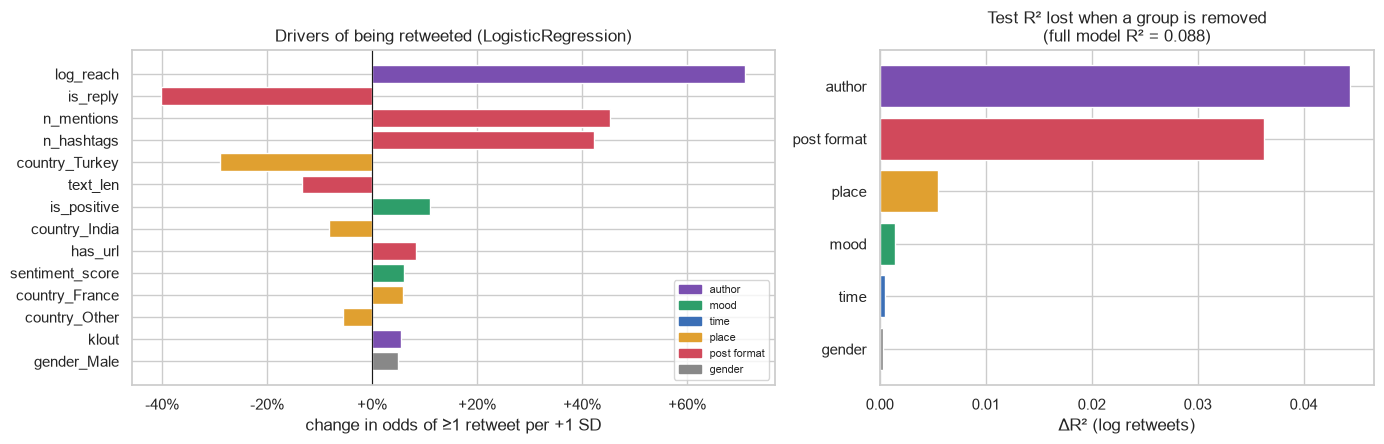

In [24]:
coef = pd.Series(logreg.coef_[0], index=X_all.columns)
group_of = {c: g for g in GROUPS for c in group_cols(g, X_all.columns)}
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:14])[::-1]
group_palette = {"author": "#7a4fb0", "mood": "#2e9e6a", "time": "#3b6fb6", "place": "#e0a030", "post format": "#d1495b", "gender": "#888888"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].barh(top.index, np.exp(top.values) - 1, color=[group_palette[group_of[c]] for c in top.index])
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("change in odds of ≥1 retweet per +1 SD")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
axes[0].set_title("Drivers of being retweeted (LogisticRegression)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_palette.values()]
axes[0].legend(handles, group_palette.keys(), loc="lower right", fontsize=8)
axes[1].barh(abl.index[::-1], abl["R2 drop when removed"][::-1], color=[group_palette[g] for g in abl.index[::-1]])
axes[1].set_title(f"Test R² lost when a group is removed\n(full model R² = {full_r2:.3f})")
axes[1].set_xlabel("ΔR² (log retweets)")
plt.tight_layout()
save("5_1_drivers")
plt.show()

RESULTS["regression"] = {
    "table": reg_table.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "cv_r2_mean": round(float(cv_r2.mean()), 4),
    "cv_r2_std": round(float(cv_r2.std()), 4),
    "cv_r2_folds": [round(float(v), 4) for v in cv_r2],
    "ablation": abl.round(4).reset_index().rename(columns={"index": "group"}).to_dict("records"),
}
RESULTS["logistic"] = {
    "table": logit_table.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "top_odds_change_per_sd": (np.exp(coef.reindex(coef.abs().sort_values(ascending=False).index[:8])) - 1).round(3).to_dict(),
}

## 6. Bias–variance

Two views of the same question: is the model too simple (high bias) or too flexible (high variance)?

- **Left (model complexity):** we add the tweet's words (TF-IDF, ~20k columns) to the features and sweep the Ridge penalty α. A small α lets the model memorize the training tweets: train error falls while test error rises (variance). A large α flattens everything (bias).
- **Right (learning curve):** LinearRegression on the 33 metadata features, trained on growing slices. Train and test error meet quickly at a high level, the signature of **high bias**: more rows will not help; better features would.

alpha=0.01      train RMSE=0.3275 test RMSE=0.5281 test R²=-0.2823


alpha=0.0316    train RMSE=0.3300 test RMSE=0.5077 test R²=-0.1849


alpha=0.1       train RMSE=0.3363 test RMSE=0.4838 test R²=-0.0762


alpha=0.316     train RMSE=0.3490 test RMSE=0.4604 test R²=0.0252


alpha=1         train RMSE=0.3688 test RMSE=0.4425 test R²=0.0996


alpha=3.16      train RMSE=0.3922 test RMSE=0.4323 test R²=0.1408


... (8 outputs left out)

alpha=1e+05     train RMSE=0.4682 test RMSE=0.4545 test R²=0.0501


alpha=3.16e+05  train RMSE=0.4751 test RMSE=0.4606 test R²=0.0246


alpha=1e+06     train RMSE=0.4791 test RMSE=0.4642 test R²=0.0094


saved figures/6_1_bias_variance.png


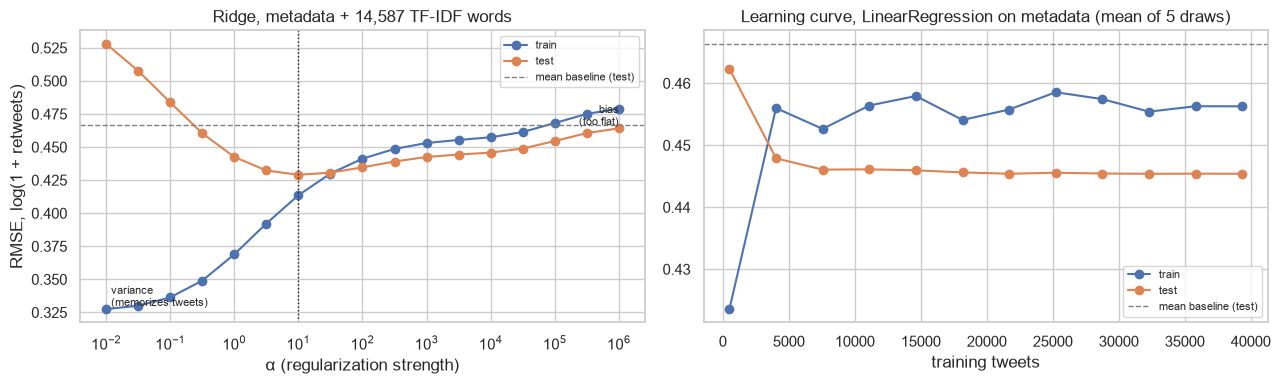

,alpha,train_RMSE,test_RMSE,test_R2
0,0.0100,0.3275,0.5281,-0.2823
1,0.0316,0.3300,0.5077,-0.1849
2,0.1000,0.3363,0.4838,-0.0762
3,0.3162,0.3490,0.4604,0.0252
4,1.0000,0.3688,0.4425,0.0996
5,3.1623,0.3922,0.4323,0.1408
6,10.0000,0.4135,0.4290,0.1538
7,31.6228,0.4300,0.4306,0.1473
8,100.0000,0.4412,0.4346,0.1315
9,316.2278,0.4486,0.4391,0.1136


In [25]:
tfidf = TfidfVectorizer(min_df=3, max_features=20000)
T_tr = tfidf.fit_transform(capped.text.iloc[tr_idx])
T_te = tfidf.transform(capped.text.iloc[te_idx])
M_tr, M_te = sparse.hstack([sparse.csr_matrix(Xs_tr), T_tr]).tocsr(), sparse.hstack([sparse.csr_matrix(Xs_te), T_te]).tocsr()
alphas = np.logspace(-2, 6, 17)
curve = []
for a in alphas:
    r = Ridge(alpha=a, solver="sparse_cg", max_iter=5000).fit(M_tr, y_tr)
    curve.append((a, rmse(y_tr, r.predict(M_tr)), rmse(y_te, r.predict(M_te)), r2_score(y_te, r.predict(M_te))))
    log.info("alpha=%-9.3g train RMSE=%.4f test RMSE=%.4f test R²=%.4f", *curve[-1])
curve = pd.DataFrame(curve, columns=["alpha", "train_RMSE", "test_RMSE", "test_R2"])
best_alpha = curve.loc[curve.test_RMSE.idxmin()]

sizes = np.unique(np.linspace(500, len(tr_idx), 12).astype(int))
rng = np.random.default_rng(SEED)
lc = []
for n in sizes:
    for rep_i in range(5):  # average 5 random subsets per size to smooth out heavy-tailed draws
        sub = rng.choice(len(tr_idx), n, replace=False)
        m = LinearRegression().fit(Xs_tr[sub], y_tr[sub])
        lc.append((n, rmse(y_tr[sub], m.predict(Xs_tr[sub])), rmse(y_te, m.predict(Xs_te))))
lc = pd.DataFrame(lc, columns=["n", "train_RMSE", "test_RMSE"]).groupby("n", as_index=False).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogx(curve.alpha, curve.train_RMSE, "o-", label="train")
axes[0].semilogx(curve.alpha, curve.test_RMSE, "o-", label="test")
axes[0].axvline(best_alpha.alpha, color="k", ls=":", lw=1)
axes[0].axhline(rmse(y_te, baseline_pred), color="gray", ls="--", lw=1, label="mean baseline (test)")
axes[0].annotate("variance\n(memorizes tweets)", xy=(0.012, curve.train_RMSE.iloc[0]), fontsize=8, va="bottom")
axes[0].annotate("bias\n(too flat)", xy=(alphas[-1], curve.test_RMSE.iloc[-1]), fontsize=8, ha="right", va="bottom")
axes[0].set_title(f"Ridge, metadata + {T_tr.shape[1]:,} TF-IDF words")
axes[0].set_xlabel("α (regularization strength)")
axes[0].set_ylabel("RMSE, log(1 + retweets)")
axes[0].legend(fontsize=8)
axes[1].plot(lc.n, lc.train_RMSE, "o-", label="train")
axes[1].plot(lc.n, lc.test_RMSE, "o-", label="test")
axes[1].axhline(rmse(y_te, baseline_pred), color="gray", ls="--", lw=1, label="mean baseline (test)")
axes[1].set_title("Learning curve, LinearRegression on metadata (mean of 5 draws)")
axes[1].set_xlabel("training tweets")
axes[1].legend(fontsize=8)
plt.tight_layout()
save("6_1_bias_variance")
plt.show()
RESULTS["bias_variance"] = {
    "best_alpha": float(best_alpha.alpha),
    "ridge_text_best_test_r2": round(float(best_alpha.test_R2), 4),
    "ridge_text_smallest_alpha": {"train_RMSE": round(float(curve.train_RMSE.iloc[0]), 4), "test_RMSE": round(float(curve.test_RMSE.iloc[0]), 4)},
    "metadata_linreg_test_r2": round(float(full_r2), 4),
}
curve.round(4)

**Reading it:** the metadata-only model sits on a flat learning curve where train and test error agree, so it is limited by **bias**: more tweets will not help. Adding the tweet's words and tuning α fixes part of that bias. At α ≈ 10, test R² roughly doubles over metadata alone. Below that, the model memorizes training tweets; above it, the penalty flattens everything back toward the mean baseline.

Which words carry that signal? These are the largest Ridge coefficients at the best α:

saved figures/6_2_words_that_spread.png


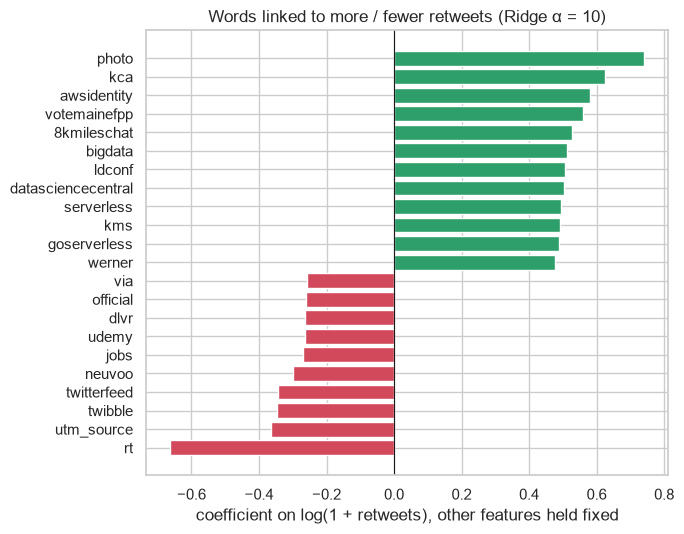

words up: ['photo', 'kca', 'awsidentity', 'votemainefpp', '8kmileschat', 'bigdata', 'ldconf', 'datasciencecentral', 'serverless', 'kms', 'goserverless', 'werner']


words down: ['rt', 'utm_source', 'twibble', 'twitterfeed', 'neuvoo', 'jobs', 'udemy', 'dlvr', 'official', 'via']


In [26]:
best_ridge = Ridge(alpha=float(best_alpha.alpha), solver="sparse_cg", max_iter=5000).fit(M_tr, y_tr)
word_coef = pd.Series(best_ridge.coef_[Xs_tr.shape[1]:], index=tfidf.get_feature_names_out())
words = pd.concat([word_coef.nsmallest(10), word_coef.nlargest(12)[::-1]])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(words.index, words.values, color=np.where(words.values > 0, "#2e9e6a", "#d1495b"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title(f"Words linked to more / fewer retweets (Ridge α = {best_alpha.alpha:g})")
ax.set_xlabel("coefficient on log(1 + retweets), other features held fixed")
plt.tight_layout()
save("6_2_words_that_spread")
plt.show()
RESULTS["bias_variance"]["top_words_up"] = word_coef.nlargest(12).round(3).to_dict()
RESULTS["bias_variance"]["top_words_down"] = word_coef.nsmallest(10).round(3).to_dict()
log.info("words up: %s", list(word_coef.nlargest(12).index))
log.info("words down: %s", list(word_coef.nsmallest(10).index))

## 7. Limitations

- **Topic skew.** The tweets were collected around AWS and cloud computing, so this is tech Twitter, not the general public; results may not transfer to lifestyle or news posts.
- **Time period.** Jan–Apr 2016. Twitter's algorithm, the Klout service (shut down in 2018) and user behavior have all changed since.
- **Lexicon labels.** "Sentiment" is a word-count score, not human judgment. Our classifier learns the lexicon well, but it drops sharply on human labels (section 3).
- **One clock for all.** `Hour` is US Mountain time for every tweet, so hour effects outside the US are not interpretable.
- **Reach is noisy, zero-inflated and concentrated.** 82% of tweets get no retweets, and one account holds 43% of all retweets. That is why we model log counts and the yes/no outcome, and cap each user at 20 tweets. Without the cap, test R² swings from −0.03 to 0.18 depending on which fold that account lands in.
- **Correlation, not causation.** Klout and Reach describe *who* posts. Higher-Klout authors may also write better or post at better times; we cannot separate these without an experiment.
- **Missing drivers.** We have no images, follower graph or posting history, which is where most real reach comes from. This shows up as high bias in section 6: even the best model explains only ~15% of the variance.

## 8. Summary (numbers computed above; also saved to `results.json`)

In [27]:
summary = pd.DataFrame(
    [
        ("Q1 mood from text", f"{best_name}", f"macro-F1 {cv_f1.mean():.2f} (5-fold CV) vs baseline {clf_table.loc['Majority baseline', 'macro_F1']:.2f}; only {air_rows.loc[best_name, 'macro_F1']:.2f} on human-labeled airline tweets"),
        ("Q2 positive vs negative retweets", "Welch t-test", f"p = {t_p:.1g}, but Cohen's d = {cohen_d:.2f} (negligible)"),
        ("Q3 mood vs weekday", "chi-square", f"p = {chi_p:.1g}, but Cramér's V = {cramers_v:.3f} (negligible)"),
        ("Q4 predict log retweets", "LinearRegression", f"test R² {full_r2:.3f} (5-fold {cv_r2.mean():.3f} ± {cv_r2.std():.3f}) vs mean baseline 0; + words (Ridge) {best_alpha.test_R2:.3f}"),
        ("Q4 retweeted at all?", "LogisticRegression", f"ROC AUC {logit_table.loc['All features', 'ROC_AUC']:.2f} vs mood-only {logit_table.loc['Mood features only', 'ROC_AUC']:.2f} vs baseline 0.50"),
        ("What drives reach", "drop-one-group ablation", " > ".join(abl.index[:4]) + " (mood and time ≈ 0)"),
    ],
    columns=["question", "method", "result"],
).set_index("question")
log.info("summary:\n%s", summary.to_string())

with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
log.info("wrote results.json")
summary

summary:
                                                       method                                                                                 result
question                                                                                                                                            
Q1 mood from text                 TF-IDF + LogisticRegression  macro-F1 0.81 (5-fold CV) vs baseline 0.27; only 0.49 on human-labeled airline tweets
Q2 positive vs negative retweets                 Welch t-test                                           p = 2e-11, but Cohen's d = 0.12 (negligible)
Q3 mood vs weekday                                 chi-square                                         p = 3e-14, but Cramér's V = 0.031 (negligible)
Q4 predict log retweets                      LinearRegression         test R² 0.088 (5-fold 0.094 ± 0.020) vs mean baseline 0; + words (Ridge) 0.154
Q4 retweeted at all?                       LogisticRegression                                    

wrote results.json


,method,result
question,,
Q1 mood from text,TF-IDF + LogisticRegression,macro-F1 0.81 (5-fold CV) vs baseline 0.27; on...
Q2 positive vs negative retweets,Welch t-test,"p = 2e-11, but Cohen's d = 0.12 (negligible)"
Q3 mood vs weekday,chi-square,"p = 3e-14, but Cramér's V = 0.031 (negligible)"
Q4 predict log retweets,LinearRegression,test R² 0.088 (5-fold 0.094 ± 0.020) vs mean b...
Q4 retweeted at all?,LogisticRegression,ROC AUC 0.72 vs mood-only 0.52 vs baseline 0.50
What drives reach,drop-one-group ablation,author > post format > place > mood (mood and ...
